# 06 — Pré-processamento: artefatos (ICA heurística × ICLabel) e normalização de amplitude
Compara variantes com o baseline **v0**, todas com os **19 canais de escalpo** (A1/A2 excluídos):

| Variante | O que muda em relação ao v0 |
|---|---|
| `v0` | — (notch 60 Hz, 1–45 Hz, CAR, rejeição robusta de janelas por amplitude) |
| `v1_full` | notch 120 Hz + rejeição muscular por janela + **ICA heurística** + escala de amplitude por participante |
| `v2_iclabel` | **ICA (infomax estendida) + ICLabel**: remove componentes olho/músculo/coração/linha/canal com prob. ≥ 0,7 |
| `v2_full` | `v2_iclabel` + escala de amplitude por participante |

Cada variante também é avaliada só com as features **invariantes à escala** (sem potências absolutas, desvio-padrão
e atividade de Hjorth).

**Histórico (21 canais, 03/10):** a rejeição muscular por janela teve efeito nulo; a ICA heurística (sem posições
dos eletrodos) limpou parcialmente e falhou nos transitórios grandes do P2; a escala por participante resolveu o
confundidor de amplitude. Resultados em `reports/v0_21canais/06_comparacao_preprocessamento.csv`.
Com os nomes dos canais (03/10) foi possível usar o **ICLabel**, classificador treinado em milhares de componentes
rotulados, que usa a topografia — o que as regras heurísticas não tinham.

**Por que a faixa 65–90 Hz para músculo (v1):** o equipamento atenua o sinal acima de ~70 Hz e em 125–148 Hz ele
encosta no piso de quantização (passo ~0,097 µV). **ICLabel e faixa alta:** o ICLabel foi treinado com 1–100 Hz;
aqui a ICA é ajustada em 1–100 Hz, mas a faixa acima de ~70 Hz é fraca nesta base.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

from src.data_io import ROOT, PROCESSED_DIR, load_subject, select_channels, SCALP_CHANNELS, FS
from src.pipeline import VARIANTS, load_variant, build_features
from src.features import feature_families, subject_distribution_features
from src.evaluation import internal_metrics, external_metrics, scale_invariant, icc1

FIG = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0
NAMES = ["v0", "v1_full", "v2_iclabel", "v2_full"]
ID_COLS = ["subject", "group", "sex", "window"]

# Gera as variantes que ainda não existem em data/processed/<variante>/ (a ICA leva ~2 min na primeira vez)
data = {}
for n in NAMES:
    if not (PROCESSED_DIR / n / "features_windows.parquet").exists():
        build_features(VARIANTS[n], verbose=False)
    data[n] = load_variant(n)
FEATS = [c for c in data["v0"][0].columns if c not in ID_COLS]
INV = scale_invariant(FEATS)
print(len(FEATS), "features;", len(INV), "invariantes à escala")

380 features; 247 invariantes à escala


## 1. O que cada tratamento fez

In [2]:
summ = []
for n in NAMES:
    fw, lg = data[n]
    row = {"variante": n, "janelas": lg.n_windows.sum(), "rej_amplitude": lg.rej_amplitude.sum(),
           "rej_muscular": lg.get("rej_muscle_only", pd.Series(0)).sum(), "mantidas": lg.kept.sum()}
    for c in [c for c in lg.columns if c.startswith("ica_") and c != "ica_removidos"]:
        row[c] = lg[c].sum()
    summ.append(row)
display(pd.DataFrame(summ).fillna(0).set_index("variante").astype(int).T)
for n in ["v1_full", "v2_iclabel"]:
    r = data[n][1]["ica_removidos"]
    print(f"{n}: componentes removidos por participante — mediana {r.median()}, mín {r.min()}, máx {r.max()}")

variante,v0,v1_full,v2_iclabel,v2_full
janelas,2758,2758,2758,2758
rej_amplitude,102,58,117,117
rej_muscular,0,49,0,0
mantidas,2656,2651,2641,2641
ica_muscular,0,25,0,0
ica_transitorio,0,84,0,0
ica_ocular,0,28,0,0
ica_cardiaco,0,7,0,0
ica_eye_blink,0,0,56,56
ica_muscle_artifact,0,0,27,27


v1_full: componentes removidos por participante — mediana 4.0, mín 0, máx 6
v2_iclabel: componentes removidos por participante — mediana 2.0, mín 0, máx 6


### Rótulos do ICLabel em todos os componentes (removidos ou não)

,n,proba_mediana,removidos
label,,,
brain,363,0.79,0
other,161,0.55,0
eye blink,91,0.80,56
muscle artifact,54,0.70,27
line noise,15,0.58,4


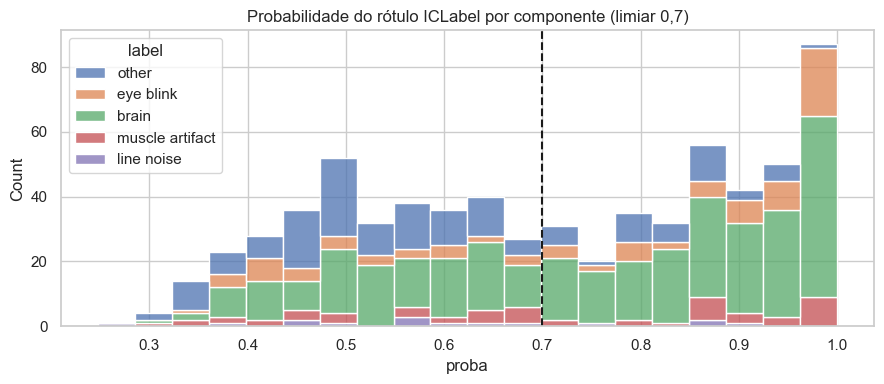

In [3]:
lab = pd.concat([pd.read_csv(PROCESSED_DIR / "ica_iclabel" / f"{s}_components.csv").assign(subject=s)
                 for s in data["v0"][1].subject])
display(lab.groupby("label").agg(n=("proba", "size"), proba_mediana=("proba", "median"),
                                 removidos=("exclude", "sum")).sort_values("n", ascending=False).round(2))
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=lab, x="proba", hue="label", multiple="stack", bins=20, ax=ax)
ax.axvline(0.7, ls="--", c="k"); ax.set_title("Probabilidade do rótulo ICLabel por componente (limiar 0,7)")
fig.tight_layout(); fig.savefig(FIG / "06_iclabel_rotulos.png", dpi=120)

### Antes × depois da ICA — P2 (o registro com mais artefato no notebook 02)

,low_ratio,kurtosis,slope_7_45,periodicity,label,exclude
0,0.663,14.731,-2.824,0.038,cerebral,False
1,0.868,11.385,-1.854,0.032,cerebral,False
2,0.863,32.249,-1.658,0.048,ocular,True
3,0.761,74.515,-1.557,0.066,transitorio,True
4,0.420,6.192,-1.687,0.036,cerebral,False
5,0.112,0.962,-2.687,0.149,cerebral,False
6,0.240,3.781,-1.454,0.052,cerebral,False
7,0.192,1.666,-1.897,0.149,cerebral,False
8,0.612,40.412,-1.244,0.075,cerebral,False
9,0.766,24.877,-1.936,0.095,cerebral,False


,label,proba,exclude
0,eye blink,0.948,True
1,eye blink,1.000,True
2,other,0.386,False
3,other,0.322,False
4,brain,0.842,False
5,brain,0.997,False
6,brain,0.580,False
7,eye blink,0.795,True
8,brain,0.951,False
9,brain,0.609,False


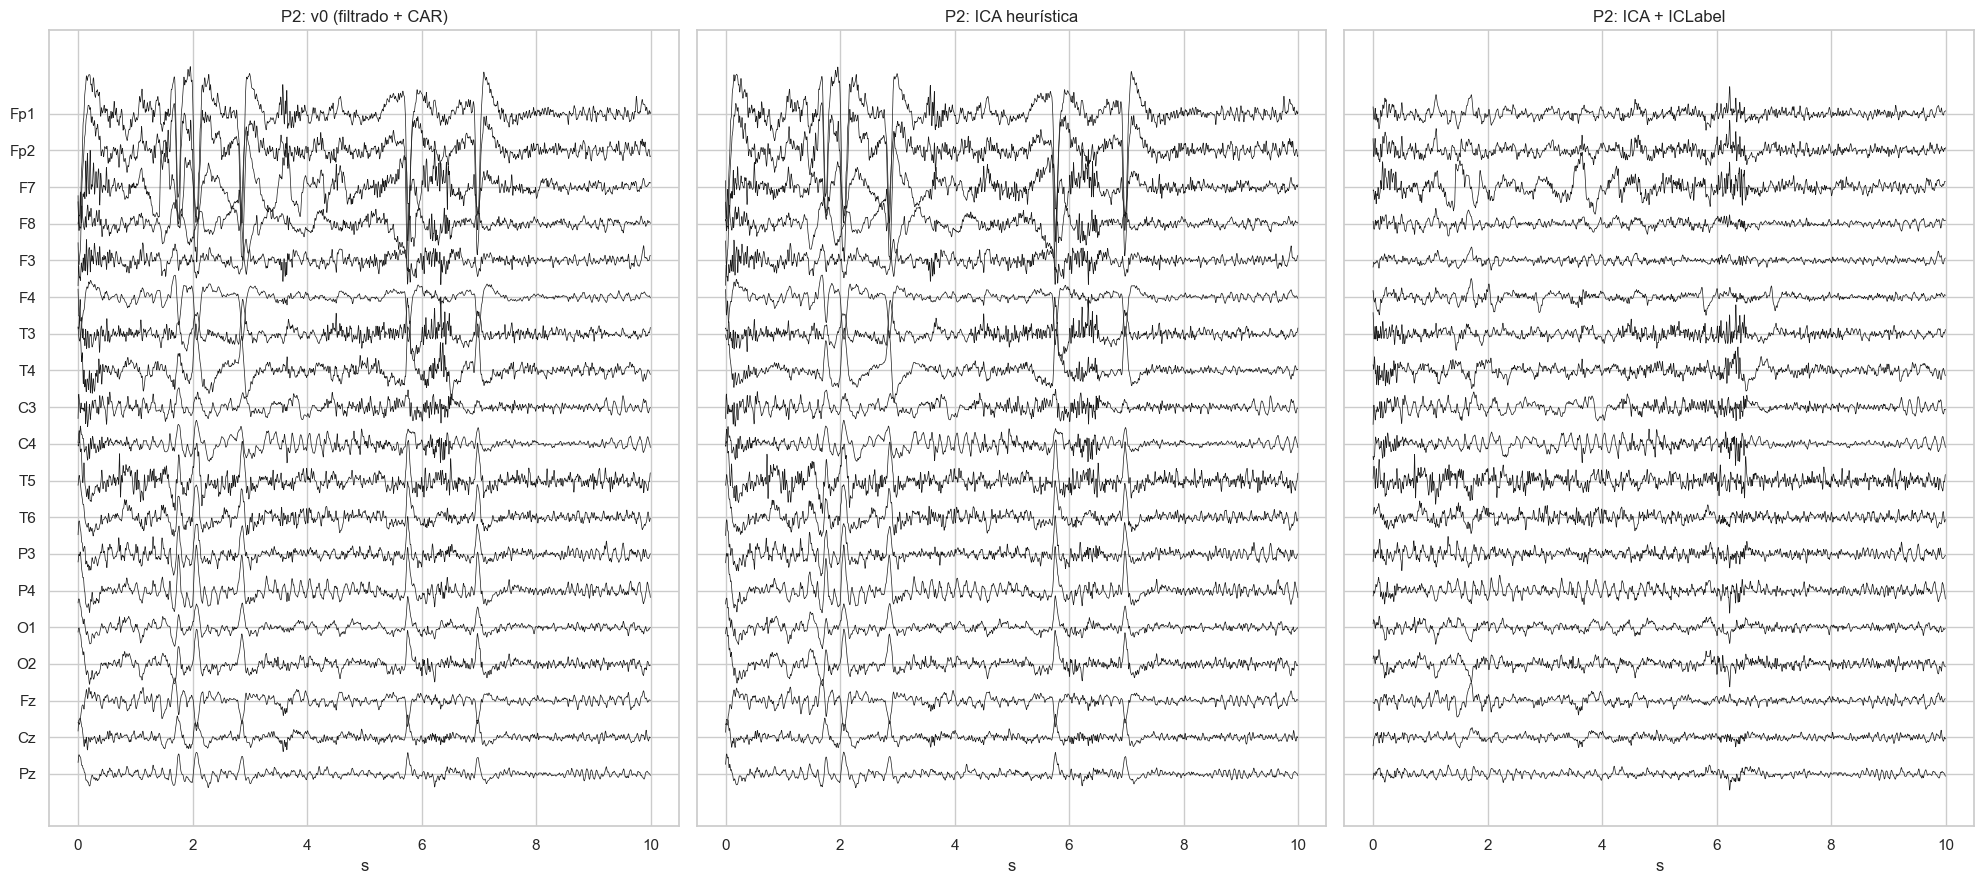

In [4]:
from src.preprocess import notch, bandpass, bad_channels, common_average_reference
subj = "P2"
x = select_channels(load_subject(subj))
y0 = bandpass(notch(x)); y0 = common_average_reference(y0, ~bad_channels(y0))
y1 = pd.read_parquet(PROCESSED_DIR / "ica" / f"{subj}.parquet").to_numpy()
y2 = pd.read_parquet(PROCESSED_DIR / "ica_iclabel" / f"{subj}.parquet").to_numpy()
display(pd.read_csv(PROCESSED_DIR / "ica" / f"{subj}_components.csv").round(3))
display(pd.read_csv(PROCESSED_DIR / "ica_iclabel" / f"{subj}_components.csv").round(3))
fig, axes = plt.subplots(1, 3, figsize=(20, 9), sharey=True)
for ax, y, t in [(axes[0], y0, "v0 (filtrado + CAR)"), (axes[1], y1, "ICA heurística"), (axes[2], y2, "ICA + ICLabel")]:
    seg = y[30 * FS: 40 * FS]
    for i in range(seg.shape[1]):
        ax.plot(np.arange(len(seg)) / FS, seg[:, i] - i * 60, lw=0.5, color="k")
    ax.set_yticks(-np.arange(len(SCALP_CHANNELS)) * 60, SCALP_CHANNELS); ax.set_xlabel("s"); ax.set_title(f"{subj}: {t}")
fig.tight_layout(); fig.savefig(FIG / "06_ica_antes_depois_P2.png", dpi=120)

## 2. Qualidade do sinal: curtose
Curtose média entre canais, por janela, resumida por participante (mediana). Gaussiano = 0; caudas pesadas =
transitórios (piscada, movimento, fala). Uma limpeza eficaz deve baixar a curtose.

,mean,25%,50%,75%,max
v0,2.36,1.66,2.15,2.84,6.51
v1_full,2.19,1.47,1.85,2.55,7.36
v2_iclabel,2.03,1.40,1.91,2.57,4.54
v2_full,2.03,1.40,1.91,2.57,4.54


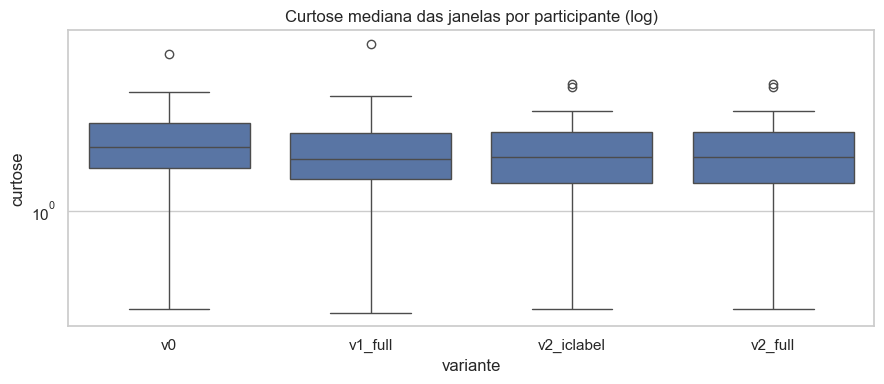

In [5]:
KURT = [c for c in FEATS if c.startswith("kurtosis__")]
kurt = pd.DataFrame({n: data[n][0].assign(k=data[n][0][KURT].mean(axis=1)).groupby("subject").k.median() for n in NAMES})
display(kurt.describe().T[["mean", "25%", "50%", "75%", "max"]].round(2))
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=kurt.melt(var_name="variante", value_name="curtose"), x="variante", y="curtose", ax=ax)
ax.set_yscale("log"); ax.set_title("Curtose mediana das janelas por participante (log)")
fig.tight_layout(); fig.savefig(FIG / "06_curtose_variantes.png", dpi=120)

## 3. Efeito indivíduo: ICC(1) por família
Fração da variância das features (nível janela) explicada pelo participante. Valores altos = "impressão digital"
individual. Normalizar amplitude deve reduzir o ICC das features dependentes de escala; limpar artefatos pode
aumentar (menos ruído dentro da pessoa) ou reduzir (artefatos idiossincráticos removidos).

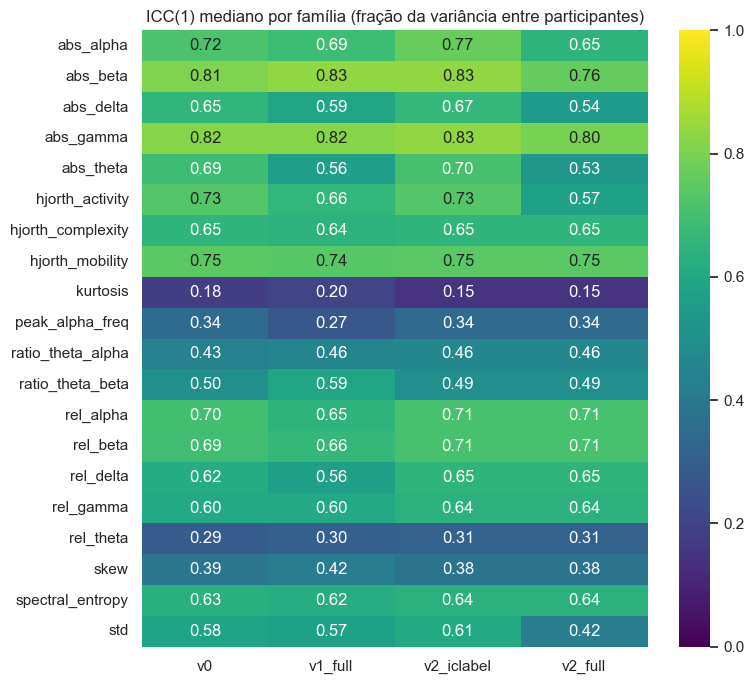

In [6]:
icc = pd.DataFrame({n: icc1(data[n][0][FEATS], data[n][0].subject) for n in NAMES})
icc_fam = icc.groupby(feature_families(FEATS)).median()
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(icc_fam, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax)
ax.set_title("ICC(1) mediano por família (fração da variância entre participantes)")
fig.tight_layout(); fig.savefig(FIG / "06_icc_variantes.png", dpi=120)

## 4. Placar por variante
Mesmas métricas do v0, no nível participante (mediana das janelas):
- **confundidores**: maior |Spearman| entre os 3 primeiros PCs e (a) a amplitude **bruta** do registro (desvio-padrão
  mediano do inventário, notebook 01 — mesma referência para todas as variantes), (b) o nº de janelas mantidas.
  Queremos **baixo**.
- **clusterização** k=2 (k-means, Ward, GMM): silhouette e ARI/p com o grupo (CTR/TCM); `distrib` = representação de
  distribuição das janelas (notebook 04), k-means.
- **referência supervisionada**: regressão logística e RF com leave-one-subject-out (nível participante) e regressão
  logística nível janela agregada por participante (AUC, com IC95% por bootstrap de participantes — com n=38 o IC
  é largo, ~±0,18, então diferenças de 0,1 entre variantes **não** são conclusivas).
- **% curtose/assimetria no top-20 do RF**: quanto o "sinal" depende de features de artefato.

In [7]:
def subject_matrix(fw, cols):
    s = fw.groupby(["subject", "group"])[cols].median().reset_index()
    return s

RAW_AMP = pd.read_csv(ROOT / "reports" / "inventario.csv").set_index("subject")["median_std_uV"]

def confounds(fw, lg, cols):
    s = subject_matrix(fw, cols)
    Z = PCA(3, random_state=SEED).fit_transform(StandardScaler().fit_transform(s[cols]))
    l = lg.set_index("subject").loc[s.subject]
    amp = max(abs(stats.spearmanr(Z[:, i], np.log(RAW_AMP.loc[s.subject]))[0]) for i in range(3))
    nwin = max(abs(stats.spearmanr(Z[:, i], l.kept)[0]) for i in range(3))
    return {"conf_amplitude": amp, "conf_n_janelas": nwin}

def clustering(fw, cols):
    s = subject_matrix(fw, cols)
    X = PCA(0.95, random_state=SEED).fit_transform(StandardScaler().fit_transform(s[cols]))
    out = {}
    for name, m in [("kmeans", KMeans(2, n_init=20, random_state=SEED)), ("ward", AgglomerativeClustering(2)),
                    ("gmm", GaussianMixture(2, covariance_type="diag", n_init=5, random_state=SEED))]:
        lab = m.fit_predict(X)
        e = external_metrics(s.group, lab)
        out |= {f"{name}_sil": internal_metrics(X, lab)["silhouette"], f"{name}_ARI": e["ARI"], f"{name}_p": e["p_assoc"]}
    d = subject_distribution_features(fw, cols, max_windows=40)
    d = d[d.n_windows_used >= 15].reset_index(drop=True)
    dc = [c for c in d.columns if "__" in c]
    Xd = PCA(0.95, random_state=SEED).fit_transform(StandardScaler().fit_transform(d[dc].fillna(d[dc].median())))
    lab = KMeans(2, n_init=20, random_state=SEED).fit_predict(Xd)
    e = external_metrics(d.group, lab)
    return out | {"distrib_ARI": e["ARI"], "distrib_p": e["p_assoc"]}

def auc_ci(y, p, n_boot=2000):
    rng = np.random.default_rng(SEED); y, p = np.asarray(y), np.asarray(p); a = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            a.append(roc_auc_score(y[i], p[i]))
    return np.percentile(a, [2.5, 97.5])

def supervised(fw, cols):
    s = subject_matrix(fw, cols)
    y = (s.group == "TCM").astype(int).to_numpy()
    lr = make_pipeline(StandardScaler(), PCA(0.95, random_state=SEED),
                       LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000))
    p_lr = cross_val_predict(lr, s[cols], y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    rf = RandomForestClassifier(450, class_weight="balanced", random_state=SEED, n_jobs=-1)
    p_rf = cross_val_predict(rf, s[cols], y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    yw = (fw.group == "TCM").astype(int).to_numpy()
    p_w = cross_val_predict(lr, fw[cols], yw, cv=LeaveOneGroupOut(), groups=fw.subject, method="predict_proba", n_jobs=-1)[:, 1]
    agg = pd.DataFrame({"s": fw.subject, "p": p_w, "y": yw}).groupby("s").mean()
    top = pd.Series(rf.fit(s[cols], y).feature_importances_, index=cols).nlargest(20).index
    art = np.mean([c.startswith(("kurtosis__", "skew__")) for c in top])
    ci = {f"{k}_IC95": "%.2f–%.2f" % tuple(auc_ci(yy, pp))
          for k, yy, pp in [("LR_AUC", y, p_lr), ("RF_AUC", y, p_rf), ("LRjanela_AUC_sujeito", agg.y, agg.p)]}
    return {"LR_AUC": roc_auc_score(y, p_lr), "LR_balacc": balanced_accuracy_score(y, p_lr >= 0.5),
            "RF_AUC": roc_auc_score(y, p_rf), "LRjanela_AUC_sujeito": roc_auc_score(agg.y, agg.p),
            "top20RF_curt_assim": art, **ci}

rows = []
for n in NAMES:
    fw, lg = data[n]
    for subset, cols in [("todas", FEATS), ("invariantes", INV)]:
        print("avaliando", n, subset, flush=True)
        rows.append({"variante": n, "features": subset, "curtose_mediana": kurt[n].median(),
                     "ICC_mediano": icc.loc[cols, n].median(),
                     **confounds(fw, lg, cols), **clustering(fw, cols), **supervised(fw, cols)})
score = pd.DataFrame(rows)
score.to_csv(ROOT / "reports" / "06_comparacao_preprocessamento.csv", index=False)
show = ["variante", "features", "curtose_mediana", "ICC_mediano", "conf_amplitude", "conf_n_janelas",
        "kmeans_sil", "kmeans_ARI", "kmeans_p", "ward_ARI", "gmm_ARI", "distrib_ARI", "distrib_p",
        "LR_AUC", "LR_AUC_IC95", "RF_AUC", "RF_AUC_IC95", "LRjanela_AUC_sujeito", "LRjanela_AUC_sujeito_IC95",
        "top20RF_curt_assim"]
score[show].round(3)

avaliando v0 todas


avaliando v0 invariantes


avaliando v1_full todas


avaliando v1_full invariantes


avaliando v2_iclabel todas


avaliando v2_iclabel invariantes


avaliando v2_full todas


avaliando v2_full invariantes


,variante,features,curtose_mediana,ICC_mediano,conf_amplitude,conf_n_janelas,kmeans_sil,kmeans_ARI,kmeans_p,ward_ARI,gmm_ARI,distrib_ARI,distrib_p,LR_AUC,LR_AUC_IC95,RF_AUC,RF_AUC_IC95,LRjanela_AUC_sujeito,LRjanela_AUC_sujeito_IC95,top20RF_curt_assim
0,v0,todas,2.150,0.633,0.743,0.329,0.160,-0.025,1.000,-0.016,-0.016,-0.029,1.000,0.577,0.38–0.75,0.525,0.32–0.71,0.627,0.43–0.80,0.35
1,v0,invariantes,2.150,0.556,0.240,0.376,0.217,-0.016,0.745,-0.024,-0.024,0.040,0.266,0.569,0.37–0.75,0.459,0.26–0.66,0.563,0.38–0.75,0.45
2,v1_full,todas,1.848,0.591,0.392,0.419,0.171,-0.002,0.515,-0.016,-0.024,-0.029,1.000,0.585,0.41–0.76,0.615,0.44–0.78,0.622,0.43–0.79,0.20
3,v1_full,invariantes,1.848,0.549,0.404,0.272,0.231,-0.002,0.342,-0.016,-0.016,0.073,0.144,0.571,0.39–0.74,0.560,0.38–0.74,0.706,0.53–0.86,0.40
4,v2_iclabel,todas,1.912,0.649,0.545,0.339,0.213,-0.022,0.721,-0.024,-0.016,-0.022,0.728,0.342,0.18–0.53,0.387,0.21–0.58,0.468,0.28–0.66,0.05
5,v2_iclabel,invariantes,1.912,0.563,0.505,0.428,0.268,-0.022,0.721,-0.024,-0.016,-0.022,0.728,0.401,0.23–0.59,0.322,0.16–0.51,0.395,0.21–0.59,0.20
6,v2_full,todas,1.912,0.600,0.367,0.424,0.232,-0.022,0.721,-0.024,-0.016,-0.022,0.728,0.373,0.20–0.56,0.346,0.18–0.53,0.493,0.31–0.69,0.10
7,v2_full,invariantes,1.912,0.563,0.505,0.428,0.268,-0.022,0.721,-0.024,-0.016,-0.022,0.728,0.401,0.23–0.59,0.322,0.16–0.51,0.395,0.21–0.59,0.20


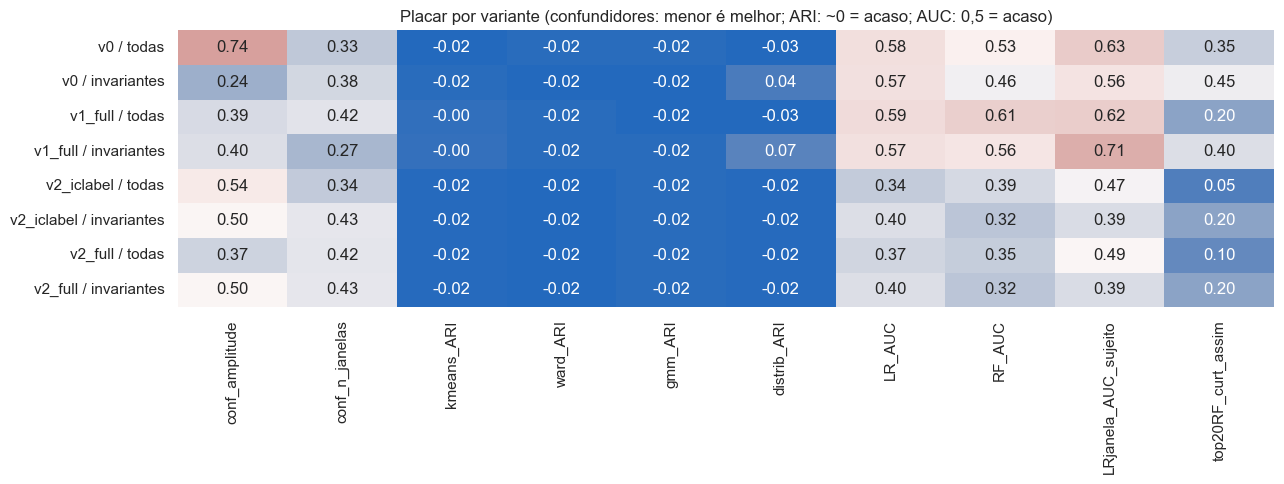

In [8]:
heat = score.set_index(score.variante + " / " + score.features)[
    ["conf_amplitude", "conf_n_janelas", "kmeans_ARI", "ward_ARI", "gmm_ARI", "distrib_ARI",
     "LR_AUC", "RF_AUC", "LRjanela_AUC_sujeito", "top20RF_curt_assim"]]
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="vlag", center=0.5, ax=ax, cbar=False)
ax.set_title("Placar por variante (confundidores: menor é melhor; ARI: ~0 = acaso; AUC: 0,5 = acaso)")
fig.tight_layout(); fig.savefig(FIG / "06_placar_variantes.png", dpi=120)

## 5. A quantidade de limpeza vira confundidor?
Nº de componentes removidos × amplitude bruta do registro (na heurística de 21 canais: Spearman 0,33, p = 0,04).

In [9]:
for n in ["v1_full", "v2_iclabel"]:
    lg = data[n][1].set_index("subject")
    r, p = stats.spearmanr(lg.ica_removidos, RAW_AMP.loc[lg.index])
    print(f"{n}: Spearman(nº removidos, amplitude bruta) = {r:.2f} (p = {p:.3f}) | removidos por grupo:",
          lg.groupby("group").ica_removidos.median().to_dict())

v1_full: Spearman(nº removidos, amplitude bruta) = 0.40 (p = 0.013) | removidos por grupo: {'CTR': 4.0, 'TCM': 3.0}
v2_iclabel: Spearman(nº removidos, amplitude bruta) = 0.10 (p = 0.544) | removidos por grupo: {'CTR': 2.0, 'TCM': 2.0}
